# Credit Card Fraud Detection Project

In [6]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
sns.set_palette("Set2")

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import(
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler




In [7]:
df=pd.read_csv("creditcard.csv")



In [8]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [9]:
df.shape

(284807, 31)

In [10]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [11]:
missing = df.isnull().sum()
missing

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [12]:
if missing.sum() == 0:
    print(' No missing values found! Dataset is clean.')
else:
    print(missing[missing > 0])

print()

 No missing values found! Dataset is clean.



In [13]:
duplicates = df.duplicated().sum()
print(f'Duplicate Rows: {duplicates}')
if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print(f'Duplicates removed. New shape: {df.shape}')
else:
    print('No duplicate rows found!')

Duplicate Rows: 1081
Duplicates removed. New shape: (283726, 31)


In [14]:
#EDA
class_counts = df['Class'].value_counts()
class_pct    = df['Class'].value_counts(normalize=True) * 100

print('Class Distribution:')
print('=' * 40)
print(f'Legitimate (0) : {class_counts[0]:>7,}  ({class_pct[0]:.2f}%)')
print(f'Fraudulent  (1) : {class_counts[1]:>7,}  ({class_pct[1]:.4f}%)')
print('=' * 40)
print()
print('SEVERE CLASS IMBALANCE DETECTED!')
print(f'   Ratio → 1 fraud per every {int(class_counts[0]/class_counts[1])} legitimate transactions')

Class Distribution:
Legitimate (0) : 283,253  (99.83%)
Fraudulent  (1) :     473  (0.1667%)

SEVERE CLASS IMBALANCE DETECTED!
   Ratio → 1 fraud per every 598 legitimate transactions


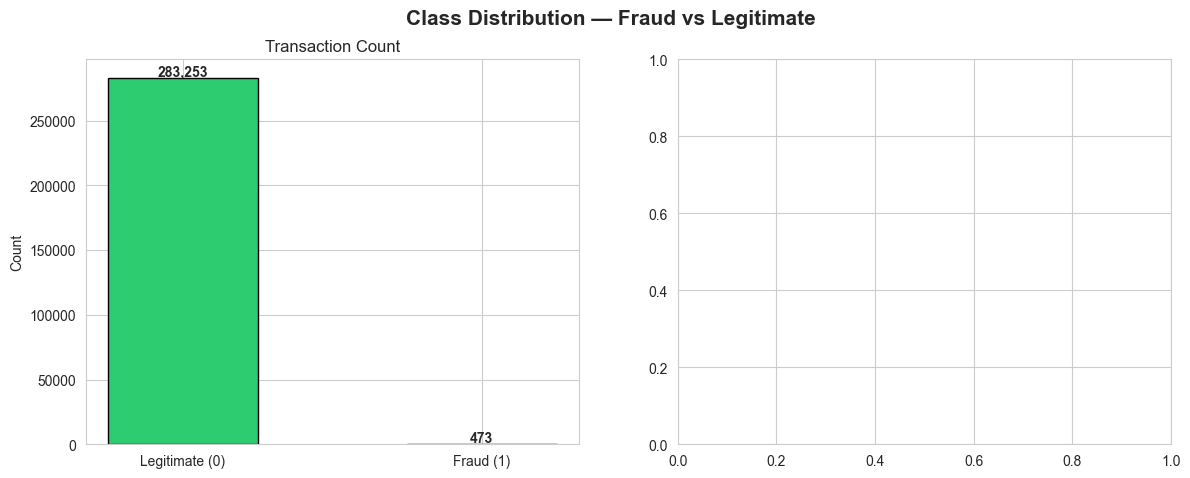

In [15]:
#Graphically
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Class Distribution — Fraud vs Legitimate', fontsize=15, fontweight='bold')

# Bar Chart
colors = ['#2ecc71', '#e74c3c']
axes[0].bar(['Legitimate (0)', 'Fraud (1)'], class_counts.values, color=colors, edgecolor='black', width=0.5)
axes[0].set_title('Transaction Count')
axes[0].set_ylabel('Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', fontweight='bold')



In [16]:
# Pie Chart
axes[1].pie(
    class_counts.values,
    labels=['Legitimate (0)', 'Fraud (1)'],
    colors=colors,
    autopct='%1.3f%%',
    startangle=90,
    explode=(0, 0.1),
    shadow=True
)
axes[1].set_title('Percentage Distribution')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(' Chart saved as class_distribution.png')

<Figure size 640x480 with 0 Axes>

 Chart saved as class_distribution.png


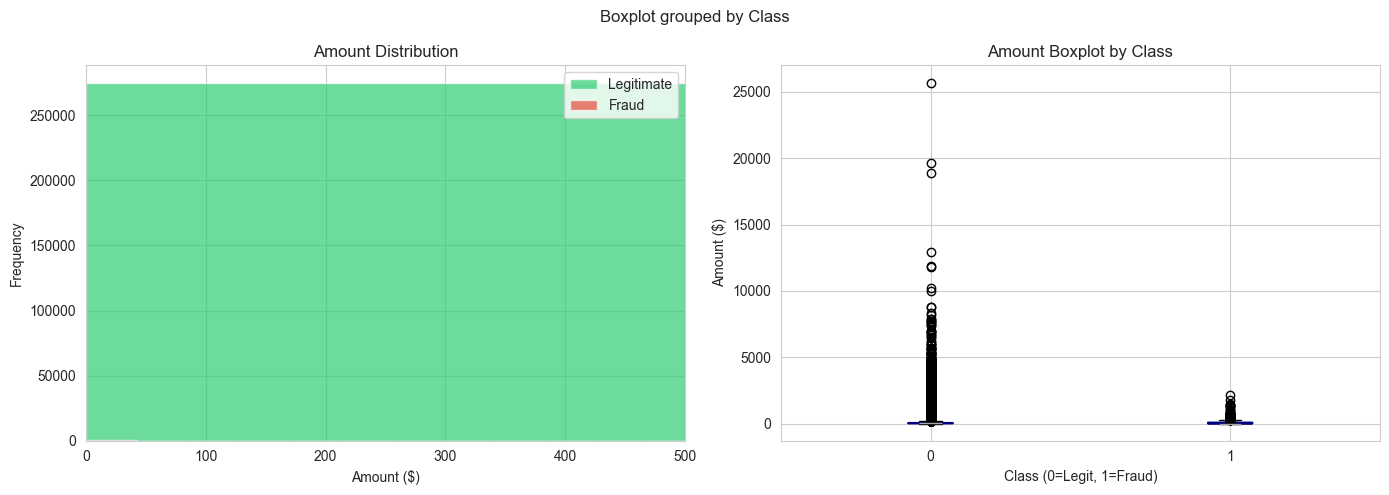

 Average Legitimate Amount : $88.41
 Average Fraud Amount      : $123.87
 Max Fraud Amount          : $2125.87


In [17]:
#  Transaction Amount Analysis 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Transaction Amount Analysis', fontsize=15, fontweight='bold')

# Amount distribution for Legit vs Fraud
legit_amount = df[df['Class'] == 0]['Amount']
fraud_amount = df[df['Class'] == 1]['Amount']

axes[0].hist(legit_amount, bins=50, color='#2ecc71', alpha=0.7, label='Legitimate')
axes[0].hist(fraud_amount, bins=50, color='#e74c3c', alpha=0.7, label='Fraud')
axes[0].set_title('Amount Distribution')
axes[0].set_xlabel('Amount ($)')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].set_xlim(0, 500)

# Boxplot
df.boxplot(column='Amount', by='Class', ax=axes[1],
           notch=True,
           boxprops=dict(color='navy'),
           patch_artist=True)
axes[1].set_title('Amount Boxplot by Class')
axes[1].set_xlabel('Class (0=Legit, 1=Fraud)')
axes[1].set_ylabel('Amount ($)')

plt.tight_layout()
plt.show()

print(f' Average Legitimate Amount : ${legit_amount.mean():.2f}')
print(f' Average Fraud Amount      : ${fraud_amount.mean():.2f}')
print(f' Max Fraud Amount          : ${fraud_amount.max():.2f}')

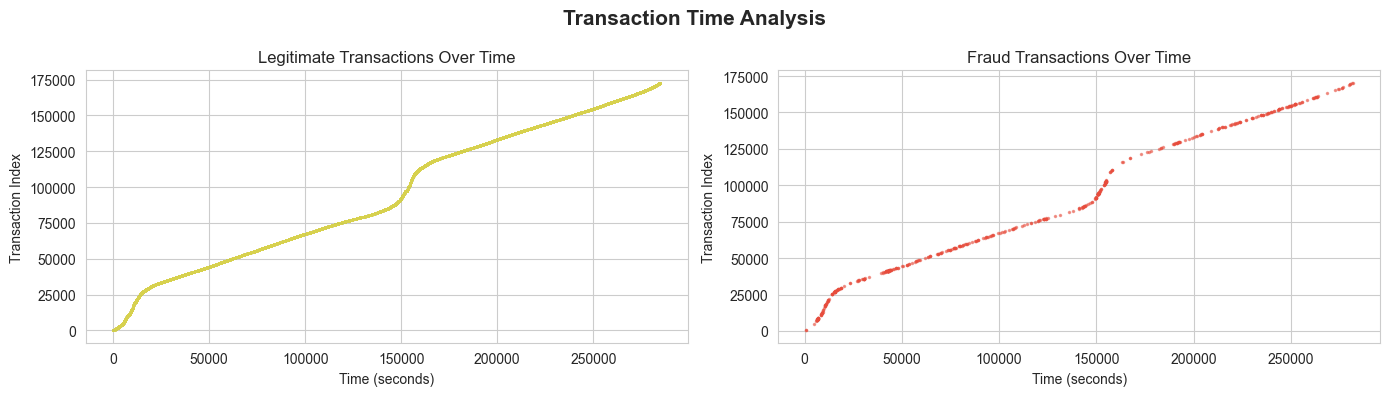

In [18]:
# Time Analysis 
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Transaction Time Analysis', fontsize=15, fontweight='bold')

legit_time = df[df['Class'] == 0]['Time']
fraud_time = df[df['Class'] == 1]['Time']

axes[0].plot(legit_time, '.', color="#d7d14e", alpha=0.1, markersize=1, label='Legitimate')
axes[0].set_title('Legitimate Transactions Over Time')
axes[0].set_xlabel('Time (seconds)')
axes[0].set_ylabel('Transaction Index')

axes[1].plot(fraud_time, '.', color='#e74c3c', alpha=0.5, markersize=3, label='Fraud')
axes[1].set_title('Fraud Transactions Over Time')
axes[1].set_xlabel('Time (seconds)')
axes[1].set_ylabel('Transaction Index')

plt.tight_layout()
plt.show()

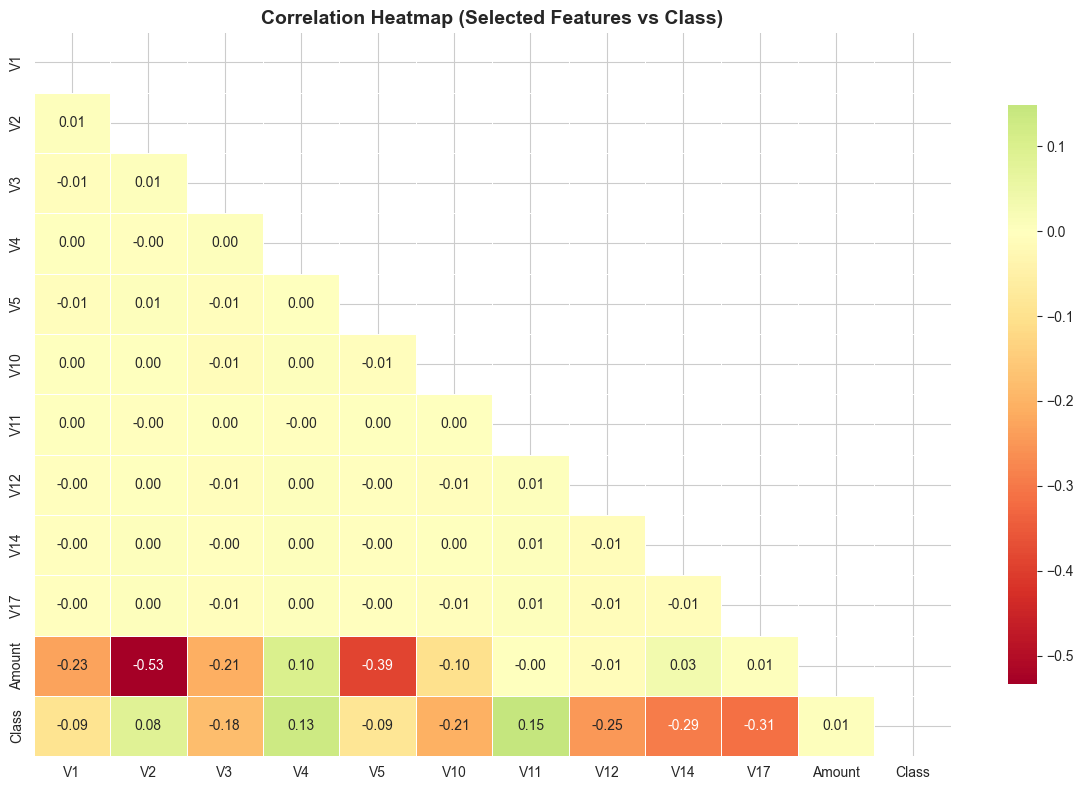

In [19]:
#  Correlation Heatmap 
# Select only a subset for readability
selected_cols = ['V1', 'V2', 'V3', 'V4', 'V5', 'V10', 'V11', 'V12',
                 'V14', 'V17', 'Amount', 'Class']

plt.figure(figsize=(12, 8))
corr_matrix = df[selected_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Heatmap (Selected Features vs Class)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()



In [20]:
# Most correlated with fraud
print('\n Top Features Correlated with Fraud (Class):')
top_corr = df.corr()['Class'].drop('Class').abs().sort_values(ascending=False).head(10)
print(top_corr)


 Top Features Correlated with Fraud (Class):
V17    0.313498
V14    0.293375
V12    0.250711
V10    0.206971
V16    0.187186
V3     0.182322
V7     0.172347
V11    0.149067
V4     0.129326
V18    0.105340
Name: Class, dtype: float64


In [21]:
# ── Scale Amount and Time ────────────────────────────────────────
scaler = StandardScaler()

df['scaled_Amount'] = scaler.fit_transform(df[['Amount']])
df['scaled_Time']   = scaler.fit_transform(df[['Time']])

# Drop original unscaled columns
df.drop(['Amount', 'Time'], axis=1, inplace=True)

print(' Amount and Time scaled successfully!')
print(f' New Shape: {df.shape}')
print()
print(' Scaled columns preview:')
df[['scaled_Amount', 'scaled_Time']].describe()



 Amount and Time scaled successfully!
 New Shape: (283726, 31)

 Scaled columns preview:


,scaled_Amount,scaled_Time
count,2.837260e+05,2.837260e+05
mean,-8.013847e-19,1.538659e-16
std,1.000002e+00,1.000002e+00
min,-3.533268e-01,-1.996823e+00
25%,-3.309625e-01,-8.552128e-01
50%,-2.654671e-01,-2.131081e-01
75%,-4.378088e-02,9.369423e-01
max,1.022476e+02,1.642362e+00


In [22]:
# Separate Features and Target 
X = df.drop('Class', axis=1)   # All columns except target
y = df['Class']                 # Target column

print(f' Features (X) Shape : {X.shape}')
print(f' Target  (y) Shape  : {y.shape}')
print()
print(' Target Distribution Before SMOTE:')
print(y.value_counts())
print(f' Imbalance Ratio: {y.value_counts()[0] / y.value_counts()[1]:.0f}:1')

 Features (X) Shape : (283726, 30)
 Target  (y) Shape  : (283726,)

 Target Distribution Before SMOTE:
Class
0    283253
1       473
Name: count, dtype: int64
 Imbalance Ratio: 599:1


In [23]:
#  Apply SMOTE
#
# SMOTE = Synthetic Minority Oversampling Technique
# Instead of simply duplicating fraud rows, SMOTE CREATES NEW synthetic
# fraud samples by interpolating between existing fraud transactions.
#
# This prevents overfitting and makes the model learn better patterns.

smote = SMOTE(random_state=42, k_neighbors=5)
X_resampled, y_resampled = smote.fit_resample(X, y)

print()
print('SMOTE Applied Successfully!')
print('=' * 45)
print(f'Before SMOTE → Legit: {y.value_counts()[0]:>7,}  |  Fraud: {y.value_counts()[1]:>4,}')
print(f'After  SMOTE → Legit: {pd.Series(y_resampled).value_counts()[0]:>7,}  |  Fraud: {pd.Series(y_resampled).value_counts()[1]:>7,}')
print('=' * 45)
print(f' New Resampled Shape: {X_resampled.shape}')


SMOTE Applied Successfully!
Before SMOTE → Legit: 283,253  |  Fraud:  473
After  SMOTE → Legit: 283,253  |  Fraud: 283,253
 New Resampled Shape: (566506, 30)


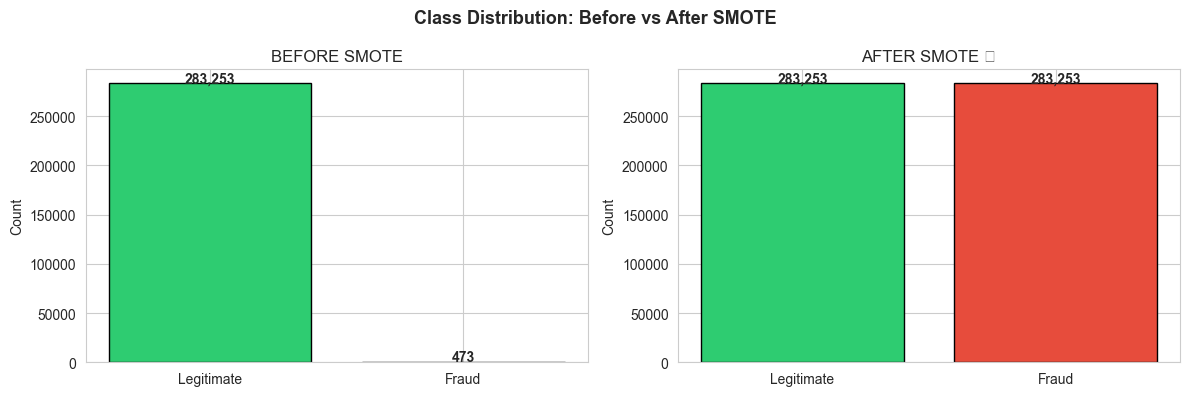

In [24]:
# ── Visualize After SMOTE ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Class Distribution: Before vs After SMOTE', fontsize=13, fontweight='bold')

colors = ['#2ecc71', '#e74c3c']

# Before
axes[0].bar(['Legitimate', 'Fraud'], y.value_counts().values, color=colors, edgecolor='black')
axes[0].set_title('BEFORE SMOTE')
axes[0].set_ylabel('Count')
for i, v in enumerate(y.value_counts().values):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', fontweight='bold')

# After
after_counts = pd.Series(y_resampled).value_counts()
axes[1].bar(['Legitimate', 'Fraud'], after_counts.values, color=colors, edgecolor='black')
axes[1].set_title('AFTER SMOTE ✅')
axes[1].set_ylabel('Count')
for i, v in enumerate(after_counts.values):
    axes[1].text(i, v + 1000, f'{v:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [25]:
#  Train / Test Split
# We split data into:
#   80% Training   → model learns from this
#   20% Testing    → we evaluate on unseen data
#
# stratify=y_resampled ensures both splits have equal fraud/legit ratio

X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled,
    test_size=0.25,
    random_state=42,
    stratify=y_resampled
)

print('Train/Test Split Done!')
print('=' * 40)
print(f'  Training Set   : {X_train.shape[0]:>7,} rows')
print(f' Testing  Set   : {X_test.shape[0]:>7,} rows')
print('=' * 40)

Train/Test Split Done!
  Training Set   : 424,879 rows
 Testing  Set   : 141,627 rows


In [26]:
#  Model 1: Logistic Regression 
# Best for: Linear relationships, fast training, interpretable
# Good baseline model — always train this first!

print(' Training Logistic Regression...')
lr_model = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
lr_model.fit(X_train, y_train)
print(' Logistic Regression trained!')

 Training Logistic Regression...
 Logistic Regression trained!


In [27]:
#  Model 2: Decision Tree 
# Best for: Non-linear patterns, interpretable, fast
# Can overfit easily — we limit max_depth to control this

print(' Training Decision Tree...')
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42, min_samples_split=5)
dt_model.fit(X_train, y_train)
print(' Decision Tree trained!')

 Training Decision Tree...
 Decision Tree trained!


In [28]:
# Model 3: Random Forest
# Best for: High accuracy, handles outliers & noise, feature importance
# 100 decision trees vote together → more reliable predictions

print('Training Random Forest (100 trees)...')
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,             # Use all CPU cores
    min_samples_split=5
)
rf_model.fit(X_train, y_train)
print(' Random Forest trained!')


Training Random Forest (100 trees)...
 Random Forest trained!


In [29]:
#now comparision of all model which i trained
# Predictions for all models 
models = {
    'Random Forest'      : rf_model,
    'Logistic Regression': lr_model,
    'Decision Tree'      : dt_model,
    
}

results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    auc    = roc_auc_score(y_test, y_prob)

    results[name] = {
        'y_pred': y_pred,
        'y_prob': y_prob,
        'auc'   : auc
    }

    print('=' * 45)
    print(f'  {name}')
    print('=' * 45)
    print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))
    print(f' AUC-ROC Score: {auc:.4f}')

print('\nComparison result of all three model')


  Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     70814
       Fraud       1.00      1.00      1.00     70813

    accuracy                           1.00    141627
   macro avg       1.00      1.00      1.00    141627
weighted avg       1.00      1.00      1.00    141627

 AUC-ROC Score: 1.0000
  Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.92      0.97      0.95     70814
       Fraud       0.97      0.92      0.95     70813

    accuracy                           0.95    141627
   macro avg       0.95      0.95      0.95    141627
weighted avg       0.95      0.95      0.95    141627

 AUC-ROC Score: 0.9890
  Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99     70814
       Fraud       0.99      0.99      0.99     70813

    accuracy                           0.99    141627
   macro avg       0.99     


Random Forest:
  True Positives  (Fraud caught)   : 70,729
  False Negatives (Fraud missed)   : 84  ← Want this LOW!
  False Positives (False alarms)   : 41
  True Negatives  (Legit correct)  : 70,773

Logistic Regression:
  True Positives  (Fraud caught)   : 65,076
  False Negatives (Fraud missed)   : 5,737  ← Want this LOW!
  False Positives (False alarms)   : 1,803
  True Negatives  (Legit correct)  : 69,011

Decision Tree:
  True Positives  (Fraud caught)   : 69,766
  False Negatives (Fraud missed)   : 1,047  ← Want this LOW!
  False Positives (False alarms)   : 848
  True Negatives  (Legit correct)  : 69,966


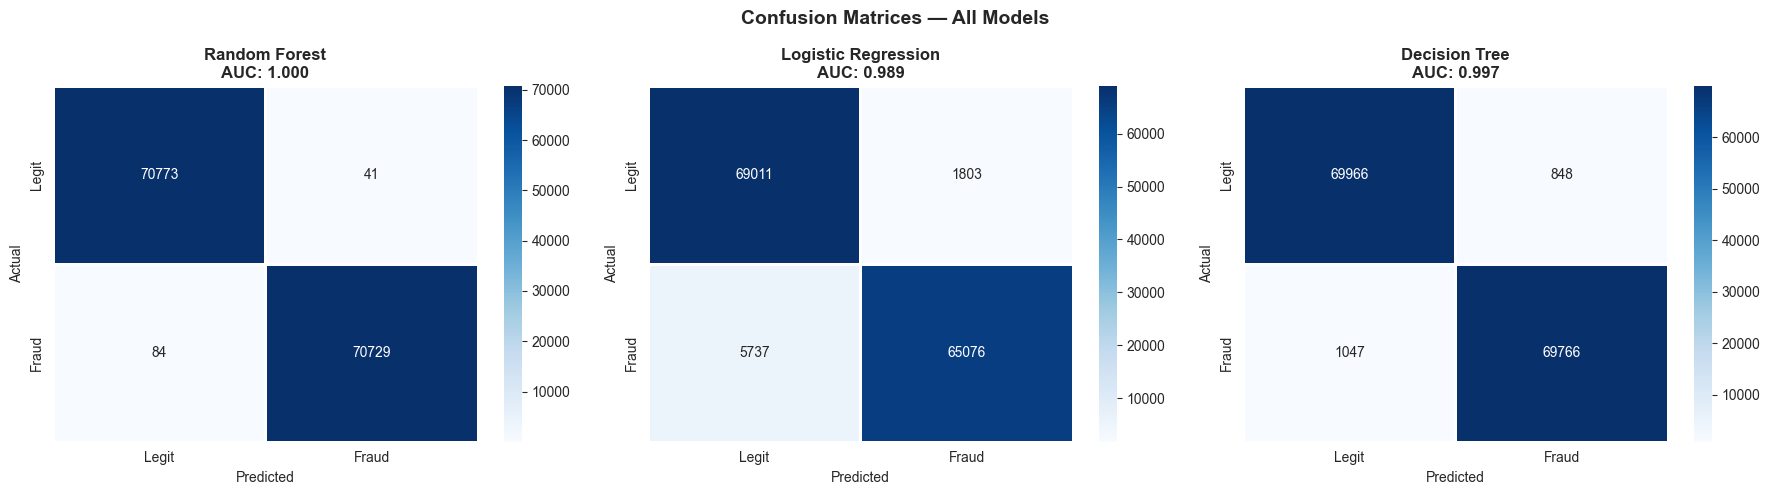

In [30]:
# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices — All Models', fontsize=14, fontweight='bold')

for idx, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        ax=axes[idx],
        xticklabels=['Legit', 'Fraud'],
        yticklabels=['Legit', 'Fraud'],
        linewidths=1
    )
    tn, fp, fn, tp = cm.ravel()
    axes[idx].set_title(f'{name}\nAUC: {res["auc"]:.3f}', fontweight='bold')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

    print(f'\n{name}:')
    print(f'  True Positives  (Fraud caught)   : {tp:,}')
    print(f'  False Negatives (Fraud missed)   : {fn:,}  ← Want this LOW!')
    print(f'  False Positives (False alarms)   : {fp:,}')
    print(f'  True Negatives  (Legit correct)  : {tn:,}')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

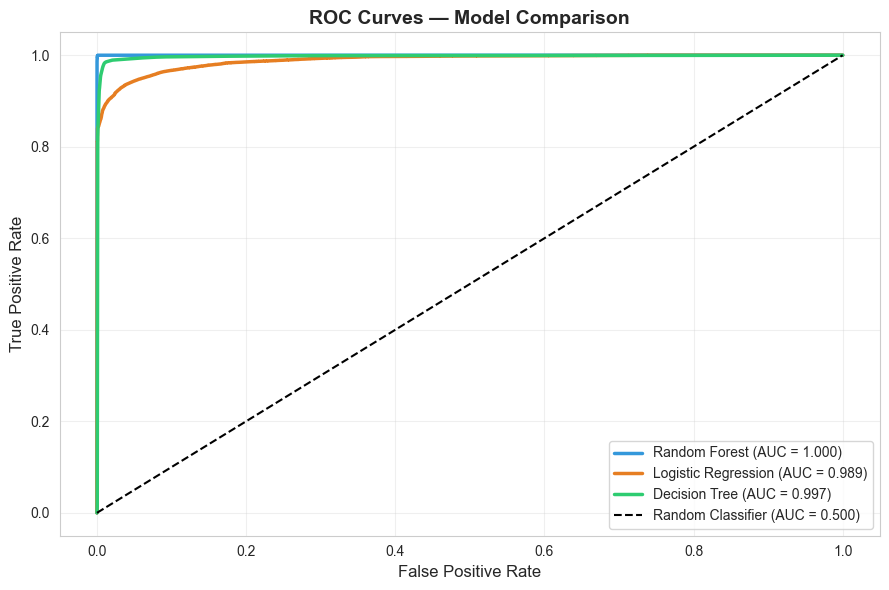

 ROC curve saved as roc_curves.png


In [31]:
from sklearn.metrics import roc_curve, roc_auc_score
# ── ROC Curves ───────────────────────────────────────────────────

# ROC Curve plots True Positive Rate vs False Positive Rate
# The higher the curve → the better the model
# AUC = Area Under the Curve (closer to 1.0 = better)

plt.figure(figsize=(9, 6))

colors_roc = ['#3498db', '#e67e22', '#2ecc71']

for (name, res), color in zip(results.items(), colors_roc):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    plt.plot(fpr, tpr, color=color, lw=2.5,
             label=f'{name} (AUC = {res["auc"]:.3f})')

# Random baseline
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.500)')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curves — Model Comparison', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print(' ROC curve saved as roc_curves.png')

In [32]:
# Summary Comparison Table 
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

summary_data = []
for name, res in results.items():
    y_pred = res['y_pred']
    summary_data.append({
        'Model'     : name,
        'Accuracy'  : f"{accuracy_score(y_test, y_pred)*100:.2f}%",
        'Precision' : f"{precision_score(y_test, y_pred)*100:.2f}%",
        'Recall'    : f"{recall_score(y_test, y_pred)*100:.2f}%",
        'F1-Score'  : f"{f1_score(y_test, y_pred)*100:.2f}%",
        'AUC-ROC'   : f"{res['auc']:.4f}"
    })

summary_df = pd.DataFrame(summary_data)
summary_df.index = summary_df.index + 1

print('\nFINAL MODEL COMPARISON TABLE')
print('=' * 75)
print(summary_df.to_string(index=False))
print('=' * 75)
print('\n Best Model: Random Forest (Highest AUC-ROC & Recall)')


FINAL MODEL COMPARISON TABLE
              Model Accuracy Precision Recall F1-Score AUC-ROC
      Random Forest   99.91%    99.94% 99.88%   99.91%  1.0000
Logistic Regression   94.68%    97.30% 91.90%   94.52%  0.9890
      Decision Tree   98.66%    98.80% 98.52%   98.66%  0.9973

 Best Model: Random Forest (Highest AUC-ROC & Recall)


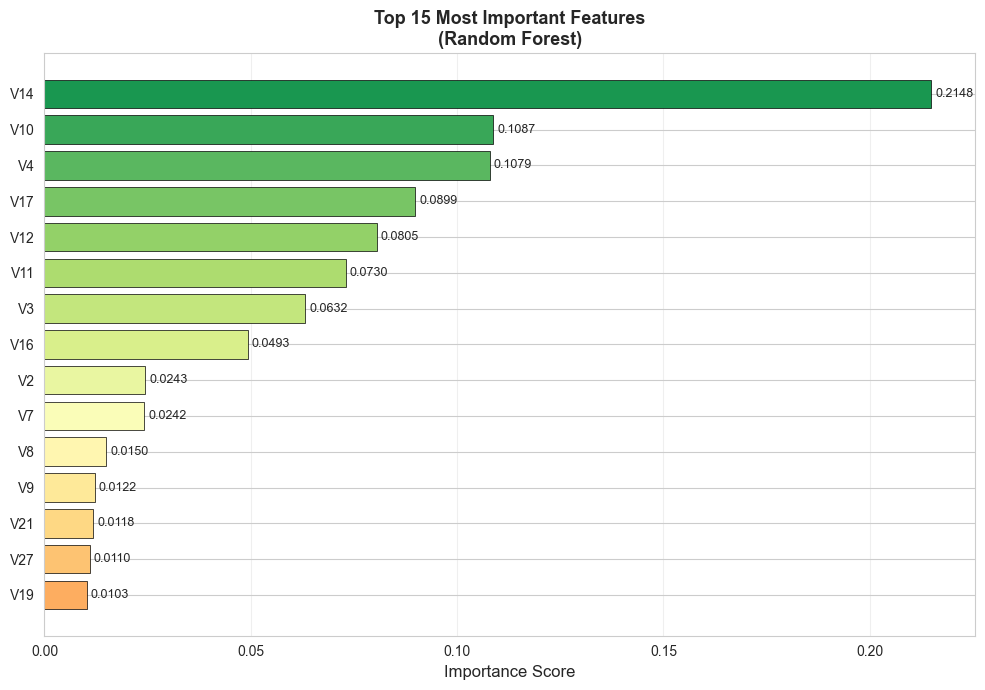

 Top 5 Fraud Indicators:
   V14                  → 0.2148
   V10                  → 0.1087
   V4                   → 0.1079
   V17                  → 0.0899
   V12                  → 0.0805


In [33]:
# Feature Importance (Random Forest) 
feature_names = X.columns.tolist()
importances   = rf_model.feature_importances_

feat_df = pd.DataFrame({
    'Feature'   : feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

# Plot Top 15 Features
plt.figure(figsize=(10, 7))
top15 = feat_df.head(15)

bars = plt.barh(top15['Feature'][::-1], top15['Importance'][::-1],
                color=plt.cm.RdYlGn(np.linspace(0.3, 0.9, 15)),
                edgecolor='black', linewidth=0.5)

plt.xlabel('Importance Score', fontsize=12)
plt.title('Top 15 Most Important Features\n(Random Forest)', fontsize=13, fontweight='bold')
plt.grid(axis='x', alpha=0.3)

for bar, val in zip(bars, top15['Importance'][::-1]):
    plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print(' Top 5 Fraud Indicators:')
for i, row in feat_df.head(5).iterrows():
    print(f'   {row["Feature"]:20s} → {row["Importance"]:.4f}')

In [34]:
# Save Best Model
 

import pickle  

# Safety check
try:
    rf_model
    print(' rf_model found! Proceeding to save...')
except NameError:
    print('ERROR: rf_model not found!')
    print('Please run Step 5 (Train Models) cell first, then re-run this cell.')
    raise

best_model_path = 'fraud_detection_rf_model.pkl'

with open(best_model_path, 'wb') as f:
    pickle.dump(rf_model, f)

print(f'Model saved as: {best_model_path}')

#Reload and Test 
with open(best_model_path, 'rb') as f:
    loaded_model = pickle.load(f)

test_pred = loaded_model.predict(X_test[:5])
print(f'\n Quick Test on 5 samples:')
print(f'   Predictions : {test_pred}')
print(f'   Actual      : {y_test[:5].values}')
print('\n Model loaded and working correctly!')


 rf_model found! Proceeding to save...
Model saved as: fraud_detection_rf_model.pkl

 Quick Test on 5 samples:
   Predictions : [1 1 0 1 0]
   Actual      : [1 1 0 1 0]

 Model loaded and working correctly!


In [35]:
# ── Predict a Single New Transaction ─────────────────────────────
#
# In a real system, you would pass live transaction data here
# For demo, we pick one row from test set

sample_transaction = X_test.iloc[0:1]   # First test sample
actual_label       = y_test.iloc[0]

prediction    = loaded_model.predict(sample_transaction)[0]
probability   = loaded_model.predict_proba(sample_transaction)[0]

print(' Single Transaction Prediction:')
print('=' * 45)
print(f'   Fraud Probability   : {probability[1]*100:.2f}%')
print(f'   Legit Probability   : {probability[0]*100:.2f}%')
print(f'   Prediction          : {" FRAUD" if prediction == 1 else " LEGITIMATE"}')
print(f'   Actual Label        : {" FRAUD" if actual_label == 1 else "✅ LEGITIMATE"}')
print('=' * 45)

 Single Transaction Prediction:
   Fraud Probability   : 99.98%
   Legit Probability   : 0.02%
   Prediction          :  FRAUD
   Actual Label        :  FRAUD
